In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:

import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models

from tensorflow.keras.applications import (
    VGG16,
    ResNet50,
    MobileNetV2,
    InceptionV3
)

from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobile_preprocess
from tensorflow.keras.applications.inception_v3 import preprocess_input as inception_preprocess

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("TensorFlow version:", tf.__version__)
print("Num GPUs Available:", len(tf.config.list_physical_devices('GPU')))

if tf.config.list_physical_devices('GPU'):
    print("GPU is available.")
else:
    print("WARNING: GPU not detected.")

TensorFlow version: 2.20.0
Num GPUs Available: 2
GPU is available.


In [2]:
SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

print("Random seed:", SEED)

Random seed: 42


In [3]:
DATASET_PATH = "/kaggle/input/datasets/swaroopkml/cifar10-pngs-in-folders/cifar10"

print("Dataset path:", DATASET_PATH)
print(os.listdir(DATASET_PATH))

Dataset path: /kaggle/input/datasets/swaroopkml/cifar10-pngs-in-folders/cifar10
['cifar10', 'test', 'train']


In [4]:

for root, dirs, files in os.walk(DATASET_PATH):
    level = root.replace(DATASET_PATH, "").count(os.sep)
    
    if level <= 2:
        print("\n" + root)
        print("Folders:", dirs[:15])
        print("Number of files:", len(files))


/kaggle/input/datasets/swaroopkml/cifar10-pngs-in-folders/cifar10
Folders: ['cifar10', 'test', 'train']
Number of files: 0

/kaggle/input/datasets/swaroopkml/cifar10-pngs-in-folders/cifar10/cifar10
Folders: ['test', 'train']
Number of files: 0

/kaggle/input/datasets/swaroopkml/cifar10-pngs-in-folders/cifar10/cifar10/test
Folders: ['airplane', 'horse', 'truck', 'automobile', 'ship', 'dog', 'bird', 'frog', 'cat', 'deer']
Number of files: 0

/kaggle/input/datasets/swaroopkml/cifar10-pngs-in-folders/cifar10/cifar10/train
Folders: ['airplane', 'horse', 'truck', 'automobile', 'ship', 'dog', 'bird', 'frog', 'cat', 'deer']
Number of files: 0

/kaggle/input/datasets/swaroopkml/cifar10-pngs-in-folders/cifar10/test
Folders: ['airplane', 'horse', 'truck', 'automobile', 'ship', 'dog', 'bird', 'frog', 'cat', 'deer']
Number of files: 0

/kaggle/input/datasets/swaroopkml/cifar10-pngs-in-folders/cifar10/test/airplane
Folders: []
Number of files: 1000

/kaggle/input/datasets/swaroopkml/cifar10-pngs-in

In [5]:

CLASS_NAMES = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

NUM_CLASSES = len(CLASS_NAMES)

CLASS_TO_INDEX = {
    name: index
    for index, name in enumerate(CLASS_NAMES)
}

INDEX_TO_CLASS = {
    index: name
    for name, index in CLASS_TO_INDEX.items()
}

print("Number of classes:", NUM_CLASSES)

for k, v in CLASS_TO_INDEX.items():
    print(v, "->", k)

Number of classes: 10
0 -> airplane
1 -> automobile
2 -> bird
3 -> cat
4 -> deer
5 -> dog
6 -> frog
7 -> horse
8 -> ship
9 -> truck


In [6]:

def load_images_from_folder(root_folder, class_names):
    
    images = []
    labels = []
    
    print("Loading images...")
    
    for class_name in class_names:
        
        class_folder = os.path.join(root_folder, class_name)
        
        if not os.path.exists(class_folder):
            print("WARNING: Folder not found:", class_folder)
            continue
        
        class_index = CLASS_TO_INDEX[class_name]
        
        files = [
            f for f in os.listdir(class_folder)
            if f.lower().endswith((".png", ".jpg", ".jpeg"))
        ]
        
        print(
            f"{class_name:12s} -> "
            f"{len(files):5d} images"
        )
        
        for filename in files:
            
            image_path = os.path.join(
                class_folder,
                filename
            )
            
            try:
                image = Image.open(image_path).convert("RGB")
                
                # Ensure CIFAR-10 dimensions
                image = image.resize((32, 32))
                
                image_array = np.array(image)
                
                images.append(image_array)
                labels.append(class_index)
                
            except Exception as e:
                print(
                    "Error loading:",
                    image_path,
                    e
                )
    
    images = np.array(images, dtype=np.uint8)
    labels = np.array(labels, dtype=np.int64)
    
    return images, labels

In [7]:
TRAIN_DIR = os.path.join(DATASET_PATH, "train")
TEST_DIR = os.path.join(DATASET_PATH, "test")

print("Train directory:", TRAIN_DIR)
print("Test directory:", TEST_DIR)

print("\nTrain exists:", os.path.exists(TRAIN_DIR))
print("Test exists:", os.path.exists(TEST_DIR))

Train directory: /kaggle/input/datasets/swaroopkml/cifar10-pngs-in-folders/cifar10/train
Test directory: /kaggle/input/datasets/swaroopkml/cifar10-pngs-in-folders/cifar10/test

Train exists: True
Test exists: True


In [8]:

X_train_full, y_train_full = load_images_from_folder(
    TRAIN_DIR,
    CLASS_NAMES
)

X_test, y_test = load_images_from_folder(
    TEST_DIR,
    CLASS_NAMES
)

print("\n================ DATASET INFORMATION ================")

print("Training images :", X_train_full.shape)
print("Training labels :", y_train_full.shape)

print("Testing images  :", X_test.shape)
print("Testing labels  :", y_test.shape)

print("Image datatype  :", X_train_full.dtype)
print("Pixel minimum   :", X_train_full.min())
print("Pixel maximum   :", X_train_full.max())

Loading images...
airplane     ->  5000 images
automobile   ->  5000 images
bird         ->  5000 images
cat          ->  5000 images
deer         ->  5000 images
dog          ->  5000 images
frog         ->  5000 images
horse        ->  5000 images
ship         ->  5000 images
truck        ->  5000 images
Loading images...
airplane     ->  1000 images
automobile   ->  1000 images
bird         ->  1000 images
cat          ->  1000 images
deer         ->  1000 images
dog          ->  1000 images
frog         ->  1000 images
horse        ->  1000 images
ship         ->  1000 images
truck        ->  1000 images

================ DATASET INFORMATION ================
Training images : (50000, 32, 32, 3)
Training labels : (50000,)
Testing images  : (10000, 32, 32, 3)
Testing labels  : (10000,)
Image datatype  : uint8
Pixel minimum   : 0
Pixel maximum   : 255


In [9]:

X_train_full = X_train_full.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("After normalization:")

print("Training dtype:", X_train_full.dtype)
print("Training min:", X_train_full.min())
print("Training max:", X_train_full.max())

print("Testing min:", X_test.min())
print("Testing max:", X_test.max())

After normalization:
Training dtype: float32
Training min: 0.0
Training max: 1.0
Testing min: 0.0
Testing max: 1.0


In [10]:

train_counts = np.bincount(
    y_train_full,
    minlength=NUM_CLASSES
)

test_counts = np.bincount(
    y_test,
    minlength=NUM_CLASSES
)

distribution_df = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Training Images": train_counts,
    "Testing Images": test_counts
})

print(distribution_df)

        Class  Training Images  Testing Images
0    airplane             5000            1000
1  automobile             5000            1000
2        bird             5000            1000
3         cat             5000            1000
4        deer             5000            1000
5         dog             5000            1000
6        frog             5000            1000
7       horse             5000            1000
8        ship             5000            1000
9       truck             5000            1000


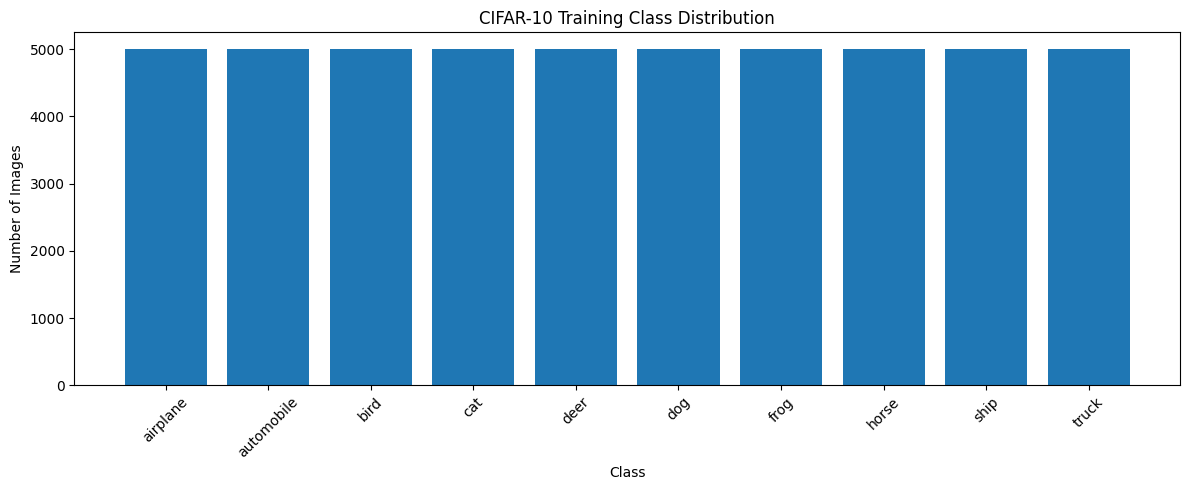

In [11]:
plt.figure(figsize=(12, 5))

plt.bar(
    CLASS_NAMES,
    train_counts
)

plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.title("CIFAR-10 Training Class Distribution")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

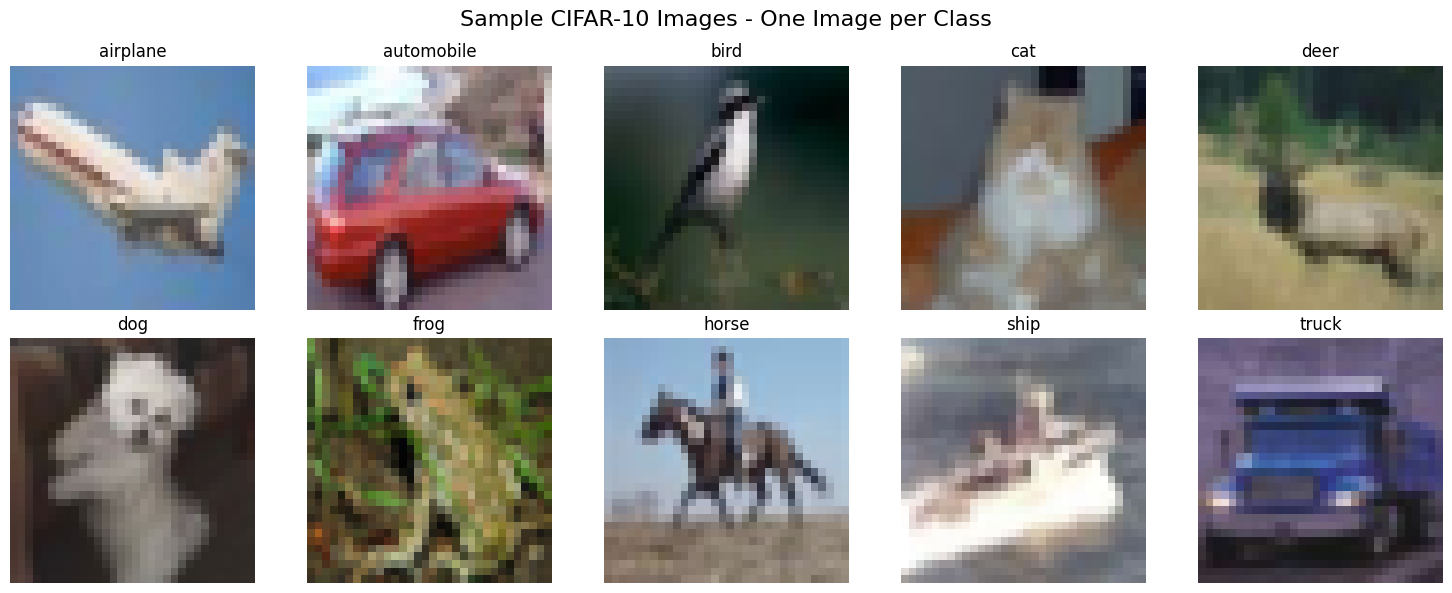

In [12]:
# ============================================================
# SAMPLE IMAGE FROM EACH CIFAR-10 CLASS
# ============================================================

plt.figure(figsize=(15, 6))

for class_index in range(NUM_CLASSES):
    
    # Find the first image belonging to this class
    image_index = np.where(
        y_train_full == class_index
    )[0][0]
    
    plt.subplot(2, 5, class_index + 1)
    
    plt.imshow(
        X_train_full[image_index]
    )
    
    plt.title(
        CLASS_NAMES[class_index]
    )
    
    plt.axis("off")

plt.suptitle(
    "Sample CIFAR-10 Images - One Image per Class",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [13]:

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.10,
    random_state=SEED,
    stratify=y_train_full
)

print("Training set   :", X_train.shape)
print("Validation set :", X_val.shape)
print("Testing set    :", X_test.shape)

Training set   : (45000, 32, 32, 3)
Validation set : (5000, 32, 32, 3)
Testing set    : (10000, 32, 32, 3)


In [14]:

y_train_cat = tf.keras.utils.to_categorical(
    y_train,
    NUM_CLASSES
)

y_val_cat = tf.keras.utils.to_categorical(
    y_val,
    NUM_CLASSES
)

y_test_cat = tf.keras.utils.to_categorical(
    y_test,
    NUM_CLASSES
)

print("Training labels:", y_train_cat.shape)
print("Validation labels:", y_val_cat.shape)
print("Testing labels:", y_test_cat.shape)

Training labels: (45000, 10)
Validation labels: (5000, 10)
Testing labels: (10000, 10)


In [15]:

BATCH_SIZE = 32

AUTOTUNE = tf.data.AUTOTUNE


def create_transfer_dataset(
    X,
    y,
    batch_size=32,
    shuffle=False
):
    
    dataset = tf.data.Dataset.from_tensor_slices(
        (X, y)
    )
    
    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=10000,
            seed=SEED
        )
    
    dataset = dataset.batch(batch_size)
    
    dataset = dataset.prefetch(
        AUTOTUNE
    )
    
    return dataset

In [16]:
# ============================================================
# VGG16 TRANSFER LEARNING MODEL
# ============================================================

def build_vgg16_model(
    dense_units=128,
    learning_rate=0.001
):
    
    base_model = VGG16(
        weights="imagenet",
        include_top=False,
        input_shape=(224, 224, 3)
    )
    
    # Freeze convolutional base
    base_model.trainable = False
    
    inputs = layers.Input(
        shape=(32, 32, 3)
    )
    
    # Resize CIFAR image
    x = layers.Resizing(
        224,
        224
    )(inputs)
    
    # Convert [0,1] -> [0,255]
    x = layers.Rescaling(
        255.0
    )(x)
    
    # ImageNet preprocessing
    x = vgg_preprocess(x)
    
    x = base_model(
        x,
        training=False
    )
    
    # Global Average Pooling
    x = layers.GlobalAveragePooling2D()(x)
    
    # Dense layer
    x = layers.Dense(
        dense_units,
        activation="relu"
    )(x)
    
    x = layers.Dropout(0.3)(x)
    
    # Output layer
    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )(x)
    
    model = models.Model(
        inputs,
        outputs
    )
    
    optimizer = tf.keras.optimizers.Adam(
        learning_rate=learning_rate
    )
    
    model.compile(
        optimizer=optimizer,
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    
    return model, base_model

In [17]:
train_ds = create_transfer_dataset(
    X_train,
    y_train_cat,
    BATCH_SIZE,
    shuffle=True
)

val_ds = create_transfer_dataset(
    X_val,
    y_val_cat,
    BATCH_SIZE,
    shuffle=False
)

test_ds = create_transfer_dataset(
    X_test,
    y_test_cat,
    BATCH_SIZE,
    shuffle=False
)

I0000 00:00:1787752014.711930     710 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1787752014.714025     710 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [18]:
vgg_model, vgg_base = build_vgg16_model(
    dense_units=128,
    learning_rate=0.001
)

vgg_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resizing (Resizing) │ (None, 224, 224,  │          0 │ input_layer_1[0]… │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ resizing[0][0]    │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ rescaling[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ rescaling[0][0]   │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ rescaling[0][0]   │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 7, 7, 512) │ 14,714,688 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 512)       │          0 │ vgg16[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │     65,664 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 10)        │      1,290 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 14,781,642 (56.39 MB)

 Trainable params: 66,954 (261.54 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [19]:
# ============================================================
# MODEL INFORMATION
# ============================================================

total_params = vgg_model.count_params()

trainable_params = np.sum([
    np.prod(v.shape)
    for v in vgg_model.trainable_weights
])

non_trainable_params = np.sum([
    np.prod(v.shape)
    for v in vgg_model.non_trainable_weights
])

print("======================================")
print("MODEL INFORMATION")
print("======================================")

print("Total parameters      :", total_params)
print("Trainable parameters  :", trainable_params)
print("Non-trainable params  :", non_trainable_params)

MODEL INFORMATION
Total parameters      : 14781642
Trainable parameters  : 66954
Non-trainable params  : 14714688


In [20]:
# ============================================================
# TRAIN VGG16 - FROZEN BASE
# ============================================================

EPOCHS = 10

start_time = time.time()

history_vgg = vgg_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

training_time = time.time() - start_time

print("\nTraining completed.")
print(
    f"Training time: {training_time / 60:.2f} minutes"
)

Epoch 1/10
   1/1407 ━━━━━━━━━━━━━━━━━━━━ 5:53:04 15s/step - accuracy: 0.1250 - loss: 5.0257

I0000 00:00:1787752033.458187     779 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1407/1407 ━━━━━━━━━━━━━━━━━━━━ 287s 194ms/step - accuracy: 0.7504 - loss: 0.7414 - val_accuracy: 0.8376 - val_loss: 0.4859
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 267s 190ms/step - accuracy: 0.8295 - loss: 0.5006 - val_accuracy: 0.8542 - val_loss: 0.4176
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 268s 190ms/step - accuracy: 0.8434 - loss: 0.4530 - val_accuracy: 0.8566 - val_loss: 0.4095
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 268s 190ms/step - accuracy: 0.8554 - loss: 0.4208 - val_accuracy: 0.8610 - val_loss: 0.4087
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 268s 190ms/step - accuracy: 0.8617 - loss: 0.3992 - val_accuracy: 0.8574 - val_loss: 0.4037
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 268s 190ms/step - accuracy: 0.8669 - loss: 0.3795 - val_accuracy: 0.8644 - val_loss: 0.3886
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 266s 189ms/step - accuracy: 0.8712 - loss: 0.3653 - val_accuracy: 0.8630 - val_loss: 0.3911
Epoch 8/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 267s 190ms/step - accuracy: 0.8

In [21]:
# ============================================================
# TRAINING RESULTS
# ============================================================

train_accuracy = history_vgg.history["accuracy"][-1]
val_accuracy = history_vgg.history["val_accuracy"][-1]

train_loss = history_vgg.history["loss"][-1]
val_loss = history_vgg.history["val_loss"][-1]

print("\n======================================")
print("VGG16 TRAINING RESULTS")
print("======================================")

print(
    f"Final Training Accuracy   : "
    f"{train_accuracy * 100:.2f}%"
)

print(
    f"Final Validation Accuracy : "
    f"{val_accuracy * 100:.2f}%"
)

print(
    f"Final Training Loss       : "
    f"{train_loss:.4f}"
)

print(
    f"Final Validation Loss     : "
    f"{val_loss:.4f}"
)

print(
    f"Training Time             : "
    f"{training_time / 60:.2f} minutes"
)

print(
    f"Total Parameters          : "
    f"{total_params:,}"
)


VGG16 TRAINING RESULTS
Final Training Accuracy   : 88.49%
Final Validation Accuracy : 85.82%
Final Training Loss       : 0.3218
Final Validation Loss     : 0.4119
Training Time             : 44.86 minutes
Total Parameters          : 14,781,642


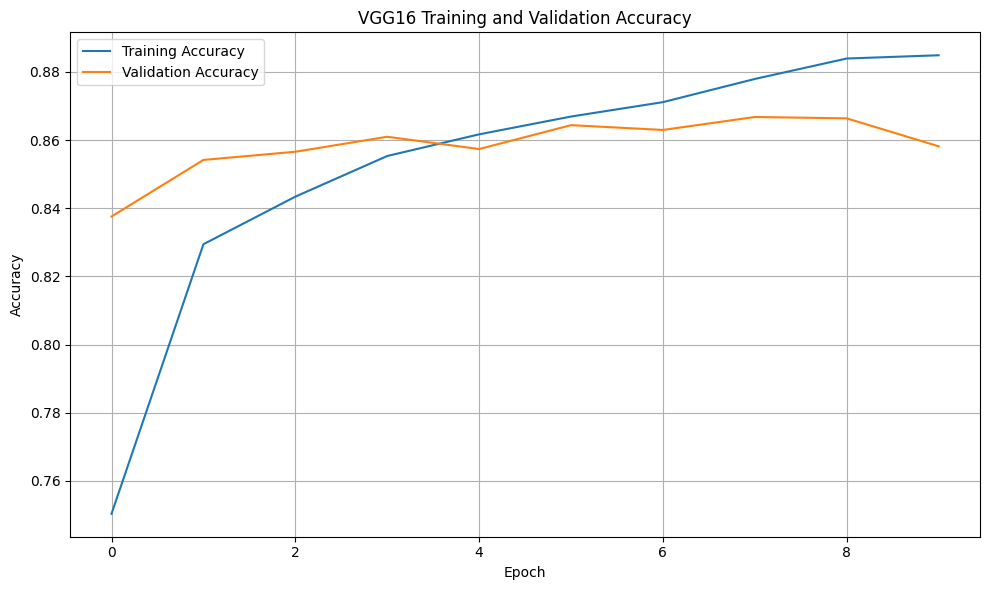

In [22]:
# ============================================================
# MANDATORY PLOT 2
# TRAINING AND VALIDATION ACCURACY
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    history_vgg.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_vgg.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "VGG16 Training and Validation Accuracy"
)

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

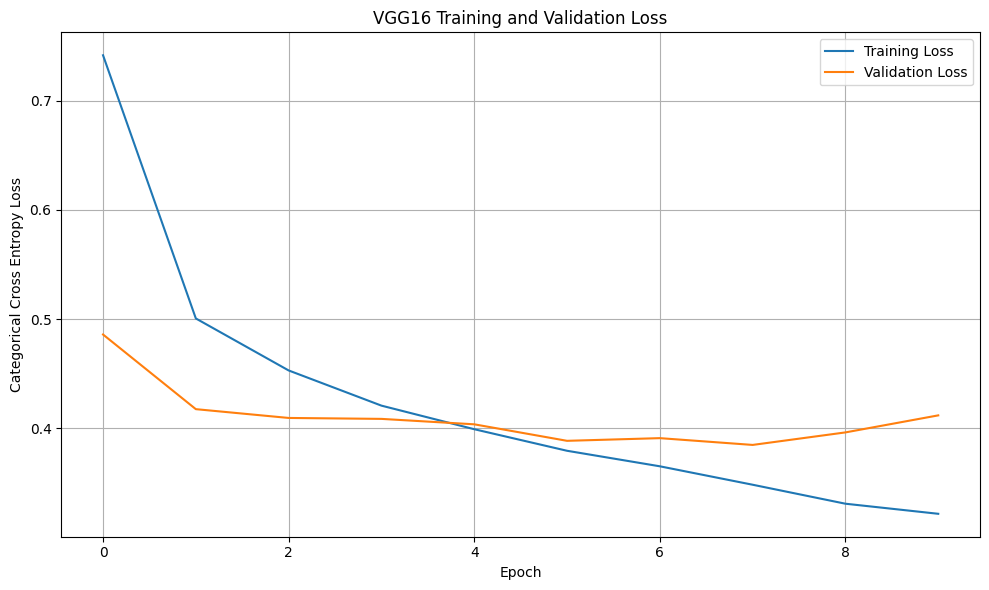

In [23]:
# ============================================================
# MANDATORY PLOTS 3 & 4
# TRAINING AND VALIDATION LOSS
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    history_vgg.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_vgg.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Categorical Cross Entropy Loss")

plt.title(
    "VGG16 Training and Validation Loss"
)

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [24]:
# ============================================================
# FINE TUNING VGG16
# ============================================================

vgg_base.trainable = True

# Freeze everything except block5
set_trainable = False

for layer in vgg_base.layers:
    
    if layer.name == "block5_conv1":
        set_trainable = True
    
    layer.trainable = set_trainable

print("Trainable layers:")
    
for layer in vgg_base.layers:
    if layer.trainable:
        print(layer.name)

Trainable layers:
block5_conv1
block5_conv2
block5_conv3
block5_pool


In [25]:

vgg_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model recompiled for fine-tuning.")

Model recompiled for fine-tuning.


In [26]:

FINE_TUNE_EPOCHS = 5

start_finetune = time.time()

history_finetune = vgg_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_TUNE_EPOCHS
)

fine_tune_time = time.time() - start_finetune

print(
    f"\nFine-tuning time: "
    f"{fine_tune_time / 60:.2f} minutes"
)

Epoch 1/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 319s 222ms/step - accuracy: 0.8487 - loss: 0.4593 - val_accuracy: 0.9010 - val_loss: 0.3140
Epoch 2/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 307s 218ms/step - accuracy: 0.9166 - loss: 0.2522 - val_accuracy: 0.9100 - val_loss: 0.2816
Epoch 3/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 308s 219ms/step - accuracy: 0.9420 - loss: 0.1715 - val_accuracy: 0.9044 - val_loss: 0.3275
Epoch 4/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 307s 218ms/step - accuracy: 0.9586 - loss: 0.1233 - val_accuracy: 0.9278 - val_loss: 0.2556
Epoch 5/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 307s 218ms/step - accuracy: 0.9668 - loss: 0.1010 - val_accuracy: 0.9114 - val_loss: 0.3049

Fine-tuning time: 25.81 minutes


In [27]:
# ============================================================
# BEFORE VS AFTER FINE-TUNING
# ============================================================

before_ft_accuracy = history_vgg.history["val_accuracy"][-1]
after_ft_accuracy = history_finetune.history["val_accuracy"][-1]

improvement = (
    after_ft_accuracy -
    before_ft_accuracy
)

print("\n======================================")
print("FINE-TUNING COMPARISON")
print("======================================")

print(
    f"Before Fine-Tuning : "
    f"{before_ft_accuracy * 100:.2f}%"
)

print(
    f"After Fine-Tuning  : "
    f"{after_ft_accuracy * 100:.2f}%"
)

print(
    f"Improvement        : "
    f"{improvement * 100:.2f} percentage points"
)


FINE-TUNING COMPARISON
Before Fine-Tuning : 85.82%
After Fine-Tuning  : 91.14%
Improvement        : 5.32 percentage points


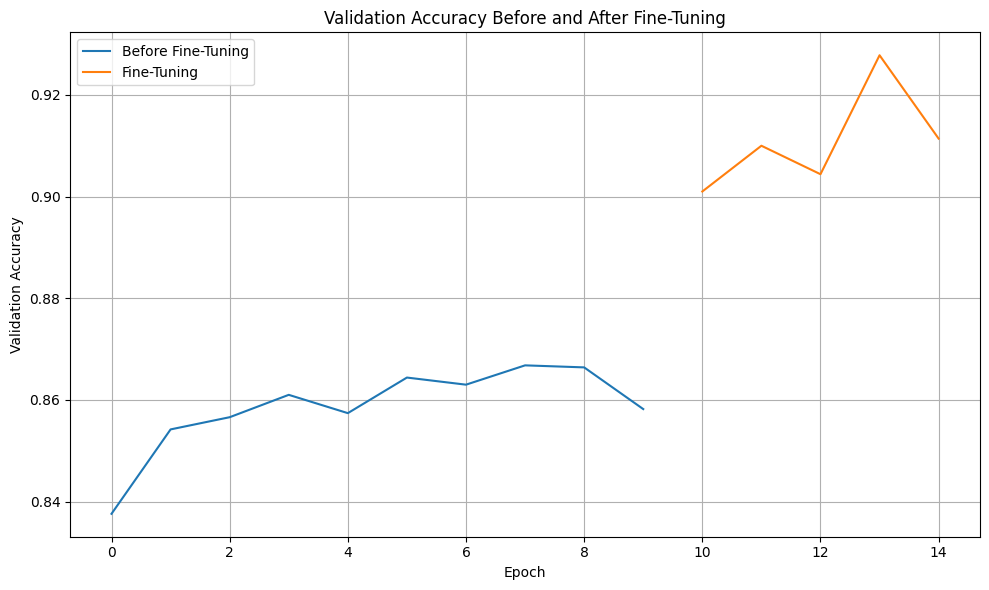

In [28]:
plt.figure(figsize=(10, 6))

plt.plot(
    history_vgg.history["val_accuracy"],
    label="Before Fine-Tuning"
)

plt.plot(
    range(
        len(history_vgg.history["val_accuracy"]),
        len(history_vgg.history["val_accuracy"]) +
        len(history_finetune.history["val_accuracy"])
    ),
    history_finetune.history["val_accuracy"],
    label="Fine-Tuning"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")

plt.title(
    "Validation Accuracy Before and After Fine-Tuning"
)

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [41]:
# ============================================================
# FINAL TEST EVALUATION
# ============================================================

test_loss, test_accuracy = vgg_model.evaluate(
    test_ds,
    verbose=1
)

print("\n======================================")
print("FINAL TEST RESULT")
print("======================================")

print(
    f"Test Loss     : {test_loss:.4f}"
)

print(
    f"Test Accuracy : "
    f"{test_accuracy * 100:.2f}%"
)

313/313 ━━━━━━━━━━━━━━━━━━━━ 55s 175ms/step - accuracy: 0.9105 - loss: 0.3431

FINAL TEST RESULT
Test Loss     : 0.3431
Test Accuracy : 91.05%


In [42]:

y_probability = vgg_model.predict(
    X_test,
    batch_size=BATCH_SIZE,
    verbose=1
)

y_pred = np.argmax(
    y_probability,
    axis=1
)

print("Prediction shape:", y_pred.shape)

313/313 ━━━━━━━━━━━━━━━━━━━━ 55s 175ms/step
Prediction shape: (10000,)


In [43]:
# ============================================================
# PERFORMANCE METRICS
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    average="weighted"
)

recall = recall_score(
    y_test,
    y_pred,
    average="weighted"
)

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted"
)

print("\n======================================")
print("FINAL PERFORMANCE METRICS")
print("======================================")

print(f"Accuracy  : {accuracy * 100:.2f}%")
print(f"Precision : {precision * 100:.2f}%")
print(f"Recall    : {recall * 100:.2f}%")
print(f"F1-score  : {f1 * 100:.2f}%")


FINAL PERFORMANCE METRICS
Accuracy  : 91.05%
Precision : 91.61%
Recall    : 91.05%
F1-score  : 91.13%


In [44]:

report = classification_report(
    y_test,
    y_pred,
    target_names=CLASS_NAMES,
    digits=4
)

print("\n======================================")
print("CLASSIFICATION REPORT")
print("======================================")

print(report)


CLASSIFICATION REPORT
              precision    recall  f1-score   support

    airplane     0.8464    0.9590    0.8992      1000
  automobile     0.9423    0.9640    0.9530      1000
        bird     0.9059    0.8950    0.9004      1000
         cat     0.7634    0.9130    0.8315      1000
        deer     0.9647    0.8460    0.9014      1000
         dog     0.8938    0.8580    0.8755      1000
        frog     0.9429    0.9410    0.9419      1000
       horse     0.9384    0.9450    0.9417      1000
        ship     0.9864    0.8680    0.9234      1000
       truck     0.9765    0.9160    0.9453      1000

    accuracy                         0.9105     10000
   macro avg     0.9161    0.9105    0.9113     10000
weighted avg     0.9161    0.9105    0.9113     10000



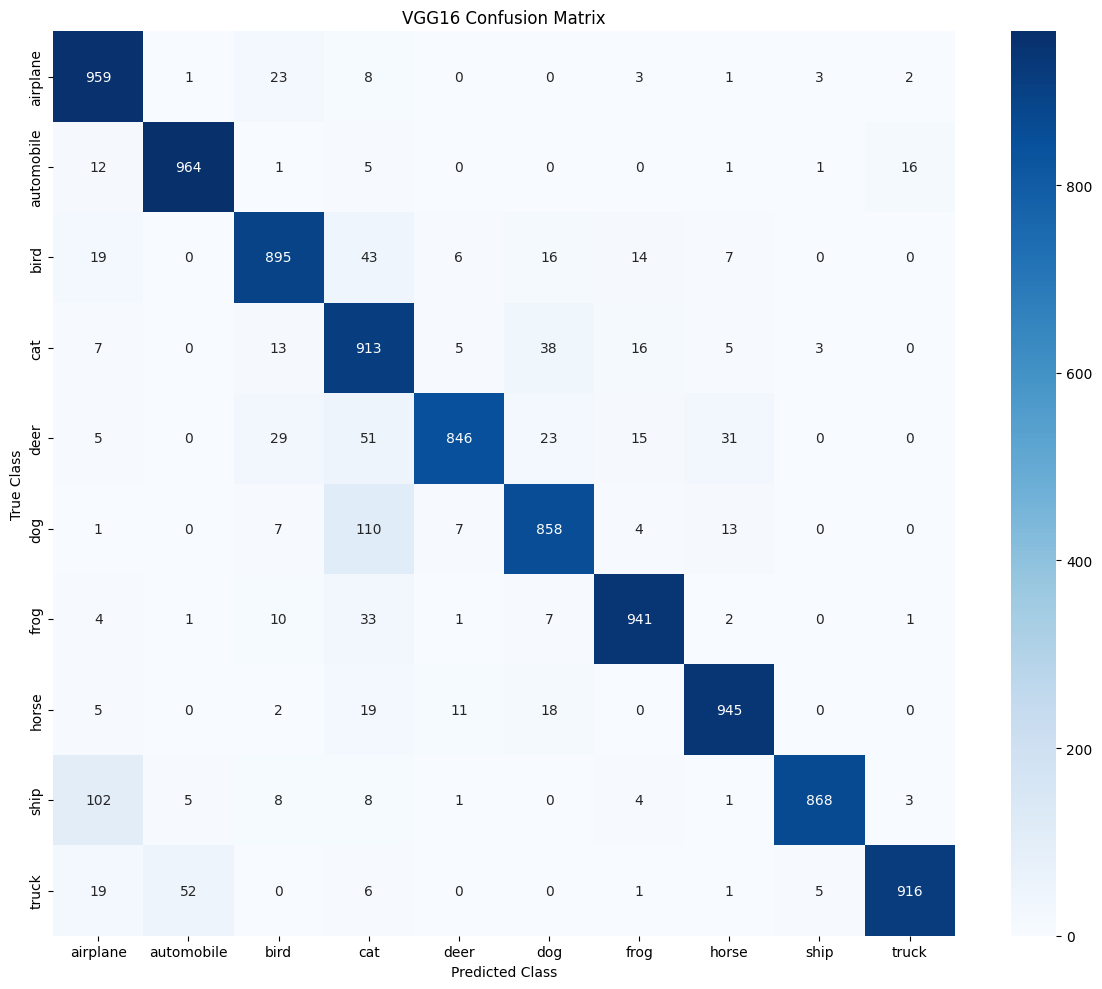

In [45]:
# ============================================================
# MANDATORY PLOT 5
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.title(
    "VGG16 Confusion Matrix"
)

plt.tight_layout()
plt.show()

In [46]:
# ============================================================
# PER-CLASS ACCURACY
# ============================================================

class_accuracy = []

for i in range(NUM_CLASSES):
    
    mask = y_test == i
    
    class_acc = np.mean(
        y_pred[mask] == y_test[mask]
    )
    
    class_accuracy.append(class_acc)

class_accuracy_df = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Accuracy (%)": np.array(class_accuracy) * 100
})

print(class_accuracy_df)

        Class  Accuracy (%)
0    airplane          95.9
1  automobile          96.4
2        bird          89.5
3         cat          91.3
4        deer          84.6
5         dog          85.8
6        frog          94.1
7       horse          94.5
8        ship          86.8
9       truck          91.6


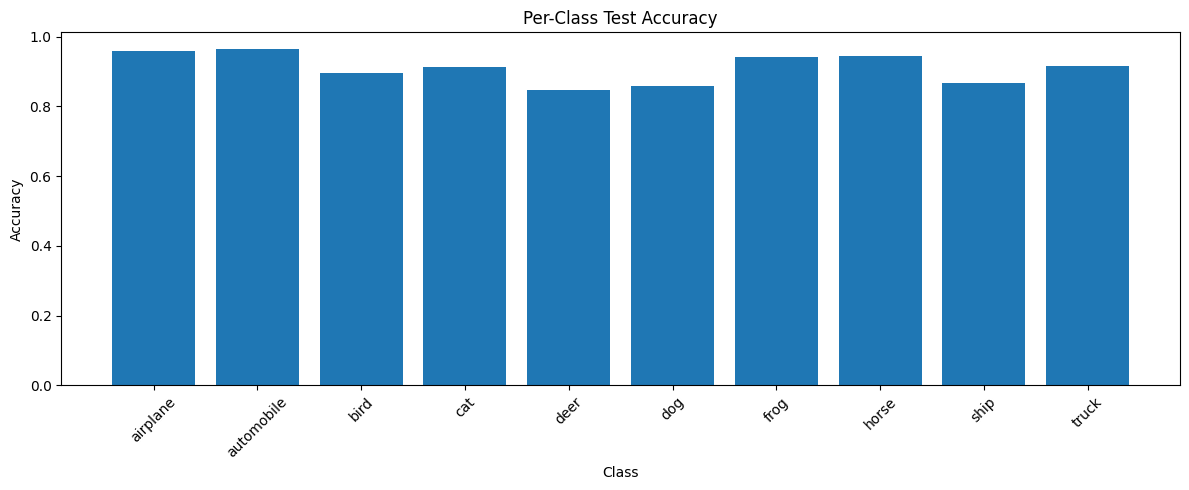

In [47]:
plt.figure(figsize=(12, 5))

plt.bar(
    CLASS_NAMES,
    class_accuracy
)

plt.ylabel("Accuracy")
plt.xlabel("Class")
plt.title("Per-Class Test Accuracy")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Number of misclassified images: 895


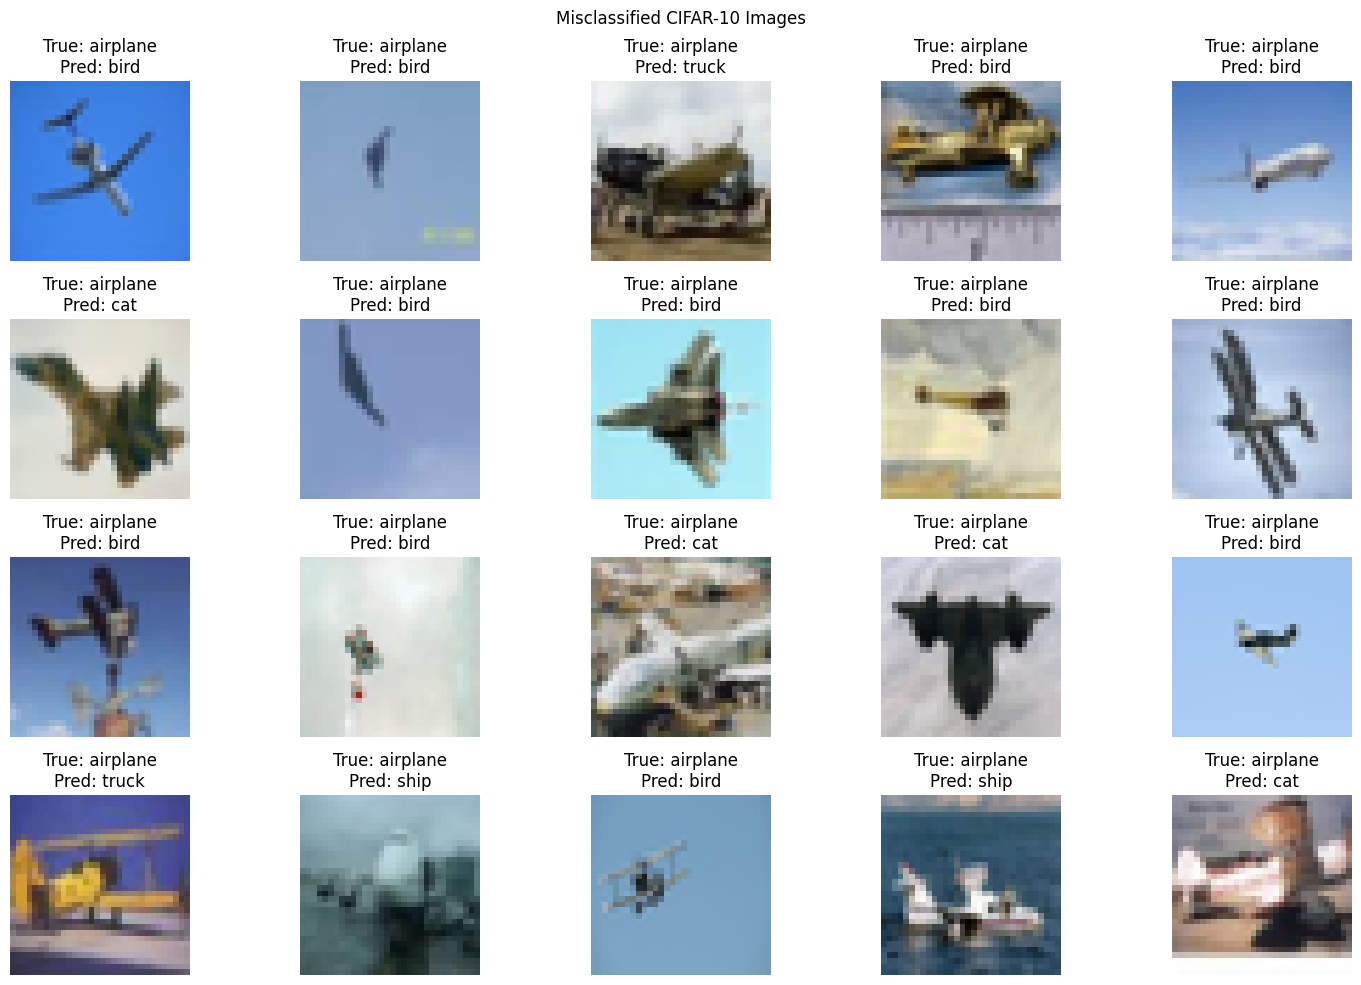

In [48]:
# ============================================================
# OPTIONAL PLOT
# MISCLASSIFIED IMAGES
# ============================================================

wrong_indices = np.where(
    y_pred != y_test
)[0]

print(
    "Number of misclassified images:",
    len(wrong_indices)
)

plt.figure(figsize=(15, 10))

num_images = min(
    20,
    len(wrong_indices)
)

for i in range(num_images):
    
    index = wrong_indices[i]
    
    plt.subplot(4, 5, i + 1)
    
    plt.imshow(X_test[index])
    
    plt.title(
        f"True: {CLASS_NAMES[y_test[index]]}\n"
        f"Pred: {CLASS_NAMES[y_pred[index]]}"
    )
    
    plt.axis("off")

plt.suptitle(
    "Misclassified CIFAR-10 Images"
)

plt.tight_layout()
plt.show()

In [49]:
# ============================================================
# SAVE VGG16 RESULT
# ============================================================

vgg_result = {
    "Model": "VGG16",
    "Parameters": vgg_model.count_params(),
    "Training Accuracy": train_accuracy * 100,
    "Validation Accuracy Before FT": before_ft_accuracy * 100,
    "Validation Accuracy After FT": after_ft_accuracy * 100,
    "Test Accuracy": accuracy * 100,
    "Precision": precision * 100,
    "Recall": recall * 100,
    "F1 Score": f1 * 100,
    "Training Time (min)": training_time / 60,
    "Fine Tuning Time (min)": fine_tune_time / 60
}

print(pd.DataFrame([vgg_result]))

   Model  Parameters  Training Accuracy  Validation Accuracy Before FT  \
0  VGG16    14781642          88.491112                      85.820001   

   Validation Accuracy After FT  Test Accuracy  Precision  Recall   F1 Score  \
0                     91.140002          91.05  91.606287   91.05  91.134606   

   Training Time (min)  Fine Tuning Time (min)  
0            44.856806               25.814692  


In [50]:
# ============================================================
# ADAM VS SGD
# ============================================================

def compile_model(model, optimizer_name, learning_rate):
    
    if optimizer_name == "Adam":
        
        optimizer = tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        )
        
    elif optimizer_name == "SGD":
        
        optimizer = tf.keras.optimizers.SGD(
            learning_rate=learning_rate,
            momentum=0.9
        )
    
    model.compile(
        optimizer=optimizer,
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

In [51]:
optimizer_results = []

for optimizer_name in ["Adam", "SGD"]:
    
    print("\n======================================")
    print("Optimizer:", optimizer_name)
    print("======================================")
    
    model, base = build_vgg16_model(
        dense_units=128,
        learning_rate=0.001
    )
    
    compile_model(
        model,
        optimizer_name,
        0.001
    )
    
    start = time.time()
    
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=3,
        verbose=1
    )
    
    elapsed = time.time() - start
    
    best_val_acc = max(
        history.history["val_accuracy"]
    )
    
    optimizer_results.append({
        "Optimizer": optimizer_name,
        "Best Validation Accuracy (%)":
            best_val_acc * 100,
        "Training Time (min)":
            elapsed / 60
    })

optimizer_df = pd.DataFrame(
    optimizer_results
)

print(optimizer_df)


Optimizer: Adam
Epoch 1/3
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 274s 193ms/step - accuracy: 0.7510 - loss: 0.7440 - val_accuracy: 0.8400 - val_loss: 0.4688
Epoch 2/3
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 268s 191ms/step - accuracy: 0.8255 - loss: 0.5054 - val_accuracy: 0.8590 - val_loss: 0.4227
Epoch 3/3
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 268s 190ms/step - accuracy: 0.8424 - loss: 0.4544 - val_accuracy: 0.8592 - val_loss: 0.4051

Optimizer: SGD
Epoch 1/3
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 273s 193ms/step - accuracy: 0.6837 - loss: 0.9322 - val_accuracy: 0.8056 - val_loss: 0.5834
Epoch 2/3
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 268s 190ms/step - accuracy: 0.7840 - loss: 0.6259 - val_accuracy: 0.8292 - val_loss: 0.4941
Epoch 3/3
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 268s 190ms/step - accuracy: 0.8096 - loss: 0.5534 - val_accuracy: 0.8424 - val_loss: 0.4571
  Optimizer  Best Validation Accuracy (%)  Training Time (min)
0      Adam                     85.920000            13.500751
1       SGD                     84.240001  

In [52]:
# ============================================================
# LEARNING RATE COMPARISON
# ============================================================

learning_rate_results = []

for lr in [0.001, 0.0001]:
    
    print("\n======================================")
    print("Learning Rate:", lr)
    print("======================================")
    
    model, base = build_vgg16_model(
        dense_units=128,
        learning_rate=lr
    )
    
    start = time.time()
    
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=3,
        verbose=1
    )
    
    elapsed = time.time() - start
    
    best_val_acc = max(
        history.history["val_accuracy"]
    )
    
    learning_rate_results.append({
        "Learning Rate": lr,
        "Best Validation Accuracy (%)":
            best_val_acc * 100,
        "Training Time (min)":
            elapsed / 60
    })

lr_df = pd.DataFrame(
    learning_rate_results
)

print(lr_df)


Learning Rate: 0.001
Epoch 1/3
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 274s 192ms/step - accuracy: 0.7517 - loss: 0.7477 - val_accuracy: 0.8464 - val_loss: 0.4515
Epoch 2/3
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 268s 190ms/step - accuracy: 0.8282 - loss: 0.5021 - val_accuracy: 0.8526 - val_loss: 0.4369
Epoch 3/3
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 268s 190ms/step - accuracy: 0.8440 - loss: 0.4518 - val_accuracy: 0.8596 - val_loss: 0.3984

Learning Rate: 0.0001
Epoch 1/3
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 274s 193ms/step - accuracy: 0.5533 - loss: 1.4196 - val_accuracy: 0.7694 - val_loss: 0.6982
Epoch 2/3
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 267s 190ms/step - accuracy: 0.7437 - loss: 0.7533 - val_accuracy: 0.8096 - val_loss: 0.5631
Epoch 3/3
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 268s 190ms/step - accuracy: 0.7836 - loss: 0.6309 - val_accuracy: 0.8254 - val_loss: 0.5032
   Learning Rate  Best Validation Accuracy (%)  Training Time (min)
0         0.0010                     85.960001            13.487040
1         0.0001     

In [53]:
# ============================================================
# DENSE UNITS COMPARISON
# ============================================================

dense_results = []

for units in [128, 256]:
    
    print("\n======================================")
    print("Dense Units:", units)
    print("======================================")
    
    model, base = build_vgg16_model(
        dense_units=units,
        learning_rate=0.001
    )
    
    start = time.time()
    
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=3,
        verbose=1
    )
    
    elapsed = time.time() - start
    
    best_val_acc = max(
        history.history["val_accuracy"]
    )
    
    dense_results.append({
        "Dense Units": units,
        "Best Validation Accuracy (%)":
            best_val_acc * 100,
        "Training Time (min)":
            elapsed / 60
    })

dense_df = pd.DataFrame(
    dense_results
)

print(dense_df)


Dense Units: 128
Epoch 1/3
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 273s 192ms/step - accuracy: 0.7473 - loss: 0.7598 - val_accuracy: 0.8474 - val_loss: 0.4482
Epoch 2/3
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 268s 190ms/step - accuracy: 0.8253 - loss: 0.5057 - val_accuracy: 0.8558 - val_loss: 0.4315
Epoch 3/3
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 269s 191ms/step - accuracy: 0.8443 - loss: 0.4570 - val_accuracy: 0.8618 - val_loss: 0.4016

Dense Units: 256
Epoch 1/3
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 274s 192ms/step - accuracy: 0.7724 - loss: 0.6803 - val_accuracy: 0.8516 - val_loss: 0.4502
Epoch 2/3
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 268s 190ms/step - accuracy: 0.8372 - loss: 0.4697 - val_accuracy: 0.8538 - val_loss: 0.4182
Epoch 3/3
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 268s 190ms/step - accuracy: 0.8537 - loss: 0.4221 - val_accuracy: 0.8606 - val_loss: 0.3991
   Dense Units  Best Validation Accuracy (%)  Training Time (min)
0          128                     86.180001            13.500476
1          256                    

In [54]:
# ============================================================
# BATCH SIZE COMPARISON
# ============================================================

batch_results = []

for batch_size in [16, 32, 64]:
    
    print("\n======================================")
    print("Batch Size:", batch_size)
    print("======================================")
    
    train_temp = create_transfer_dataset(
        X_train,
        y_train_cat,
        batch_size,
        shuffle=True
    )
    
    val_temp = create_transfer_dataset(
        X_val,
        y_val_cat,
        batch_size,
        shuffle=False
    )
    
    model, base = build_vgg16_model(
        dense_units=128,
        learning_rate=0.001
    )
    
    start = time.time()
    
    history = model.fit(
        train_temp,
        validation_data=val_temp,
        epochs=3,
        verbose=1
    )
    
    elapsed = time.time() - start
    
    best_val_acc = max(
        history.history["val_accuracy"]
    )
    
    batch_results.append({
        "Batch Size": batch_size,
        "Best Validation Accuracy (%)":
            best_val_acc * 100,
        "Training Time (min)":
            elapsed / 60
    })

batch_df = pd.DataFrame(
    batch_results
)

print(batch_df)


Batch Size: 16
Epoch 1/3
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 323s 114ms/step - accuracy: 0.7567 - loss: 0.7259 - val_accuracy: 0.8458 - val_loss: 0.4474
Epoch 2/3
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 316s 112ms/step - accuracy: 0.8245 - loss: 0.5154 - val_accuracy: 0.8574 - val_loss: 0.4073
Epoch 3/3
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 316s 112ms/step - accuracy: 0.8388 - loss: 0.4713 - val_accuracy: 0.8630 - val_loss: 0.4082

Batch Size: 32
Epoch 1/3
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 274s 193ms/step - accuracy: 0.7501 - loss: 0.7496 - val_accuracy: 0.8412 - val_loss: 0.4608
Epoch 2/3
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 267s 190ms/step - accuracy: 0.8273 - loss: 0.5012 - val_accuracy: 0.8510 - val_loss: 0.4214
Epoch 3/3
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 268s 191ms/step - accuracy: 0.8442 - loss: 0.4504 - val_accuracy: 0.8576 - val_loss: 0.4135

Batch Size: 64
Epoch 1/3
704/704 ━━━━━━━━━━━━━━━━━━━━ 265s 339ms/step - accuracy: 0.7320 - loss: 0.8054 - val_accuracy: 0.8350 - val_loss: 0.4759
Epoch 2/3
704/704 ━━━━━

In [55]:
# ============================================================
# LENET-5
# ============================================================

def build_lenet5():
    
    model = keras.Sequential([
        
        layers.Input(
            shape=(32, 32, 3)
        ),
        
        layers.Conv2D(
            6,
            kernel_size=5,
            activation="tanh",
            padding="same"
        ),
        
        layers.AveragePooling2D(
            pool_size=2
        ),
        
        layers.Conv2D(
            16,
            kernel_size=5,
            activation="tanh"
        ),
        
        layers.AveragePooling2D(
            pool_size=2
        ),
        
        layers.Flatten(),
        
        layers.Dense(
            120,
            activation="tanh"
        ),
        
        layers.Dense(
            84,
            activation="tanh"
        ),
        
        layers.Dense(
            NUM_CLASSES,
            activation="softmax"
        )
    ])
    
    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    
    return model

In [56]:
# ============================================================
# GENERIC TRAINING FUNCTION
# ============================================================

def train_and_evaluate_model(
    model,
    train_data,
    val_data,
    test_data,
    y_true,
    epochs=10,
    model_name="Model"
):
    
    print("\n")
    print("=" * 60)
    print(model_name)
    print("=" * 60)
    
    print(
        "Total parameters:",
        f"{model.count_params():,}"
    )
    
    start = time.time()
    
    history = model.fit(
        train_data,
        validation_data=val_data,
        epochs=epochs,
        verbose=1
    )
    
    training_time = time.time() - start
    
    probabilities = model.predict(
        test_data,
        verbose=1
    )
    
    predictions = np.argmax(
        probabilities,
        axis=1
    )
    
    accuracy = accuracy_score(
        y_true,
        predictions
    )
    
    precision = precision_score(
        y_true,
        predictions,
        average="weighted"
    )
    
    recall = recall_score(
        y_true,
        predictions,
        average="weighted"
    )
    
    f1 = f1_score(
        y_true,
        predictions,
        average="weighted"
    )
    
    result = {
        "Model": model_name,
        "Parameters": model.count_params(),
        "Accuracy (%)": accuracy * 100,
        "Precision (%)": precision * 100,
        "Recall (%)": recall * 100,
        "F1 Score (%)": f1 * 100,
        "Training Time (min)": training_time / 60
    }
    
    print("\nRESULTS")
    print("-" * 60)
    
    for key, value in result.items():
        
        if isinstance(value, float):
            print(f"{key:25s}: {value:.2f}")
        else:
            print(f"{key:25s}: {value}")
    
    return history, result, predictions

In [57]:
lenet_model = build_lenet5()

lenet_history, lenet_result, lenet_predictions = \
    train_and_evaluate_model(
        lenet_model,
        create_transfer_dataset(
            X_train,
            y_train_cat,
            32,
            True
        ),
        create_transfer_dataset(
            X_val,
            y_val_cat,
            32,
            False
        ),
        create_transfer_dataset(
            X_test,
            y_test_cat,
            32,
            False
        ),
        y_test,
        epochs=10,
        model_name="LeNet-5"
    )



LeNet-5
Total parameters: 83,126
Epoch 1/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.3736 - loss: 1.7705 - val_accuracy: 0.4292 - val_loss: 1.6245
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4627 - loss: 1.5223 - val_accuracy: 0.4798 - val_loss: 1.4578
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.5028 - loss: 1.4056 - val_accuracy: 0.5068 - val_loss: 1.4030
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.5315 - loss: 1.3258 - val_accuracy: 0.5178 - val_loss: 1.3678
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.5507 - loss: 1.2641 - val_accuracy: 0.5188 - val_loss: 1.3496
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.5717 - loss: 1.2129 - val_accuracy: 0.5096 - val_loss: 1.3933
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.5866 - loss: 1.1696 - val_accuracy: 0.5242 - val_loss: 1.3787
Epoch 8/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step 

In [58]:
# ============================================================
# ALEXNET
# ============================================================

def build_alexnet():
    
    model = keras.Sequential([
        
        layers.Input(
            shape=(32, 32, 3)
        ),
        
        layers.Conv2D(
            96,
            kernel_size=3,
            padding="same",
            activation="relu"
        ),
        
        layers.BatchNormalization(),
        
        layers.MaxPooling2D(
            pool_size=2
        ),
        
        layers.Conv2D(
            256,
            kernel_size=3,
            padding="same",
            activation="relu"
        ),
        
        layers.BatchNormalization(),
        
        layers.MaxPooling2D(
            pool_size=2
        ),
        
        layers.Conv2D(
            384,
            kernel_size=3,
            padding="same",
            activation="relu"
        ),
        
        layers.Conv2D(
            384,
            kernel_size=3,
            padding="same",
            activation="relu"
        ),
        
        layers.Conv2D(
            256,
            kernel_size=3,
            padding="same",
            activation="relu"
        ),
        
        layers.MaxPooling2D(
            pool_size=2
        ),
        
        layers.Flatten(),
        
        layers.Dense(
            4096,
            activation="relu"
        ),
        
        layers.Dropout(0.5),
        
        layers.Dense(
            4096,
            activation="relu"
        ),
        
        layers.Dropout(0.5),
        
        layers.Dense(
            NUM_CLASSES,
            activation="softmax"
        )
    ])
    
    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    
    return model

In [59]:
alexnet_model = build_alexnet()

alexnet_history, alexnet_result, alexnet_predictions = \
    train_and_evaluate_model(
        alexnet_model,
        create_transfer_dataset(
            X_train,
            y_train_cat,
            32,
            True
        ),
        create_transfer_dataset(
            X_val,
            y_val_cat,
            32,
            False
        ),
        create_transfer_dataset(
            X_test,
            y_test_cat,
            32,
            False
        ),
        y_test,
        epochs=10,
        model_name="AlexNet"
    )



AlexNet
Total parameters: 36,926,730
Epoch 1/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 47s 27ms/step - accuracy: 0.0976 - loss: 2.3157 - val_accuracy: 0.1000 - val_loss: 2.3045
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 31s 22ms/step - accuracy: 0.0984 - loss: 2.3121 - val_accuracy: 0.1000 - val_loss: 2.3027
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 31s 22ms/step - accuracy: 0.0962 - loss: 2.3030 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 31s 22ms/step - accuracy: 0.0993 - loss: 2.3029 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 31s 22ms/step - accuracy: 0.0978 - loss: 2.3029 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 30s 22ms/step - accuracy: 0.0982 - loss: 2.3028 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 30s 22ms/step - accuracy: 0.0999 - loss: 2.3028 - val_accuracy: 0.1000 - val_loss: 2.3027
Epoch 8/10
1407/1407 ━━━━━━━━━━━━━━━━

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [60]:
# ============================================================
# RESNET50 TRANSFER LEARNING
# ============================================================

def build_resnet50_model():
    
    base = ResNet50(
        weights="imagenet",
        include_top=False,
        input_shape=(224, 224, 3)
    )
    
    base.trainable = False
    
    inputs = layers.Input(
        shape=(32, 32, 3)
    )
    
    x = layers.Resizing(
        224,
        224
    )(inputs)
    
    x = layers.Rescaling(
        255.0
    )(x)
    
    x = resnet_preprocess(x)
    
    x = base(
        x,
        training=False
    )
    
    x = layers.GlobalAveragePooling2D()(x)
    
    x = layers.Dense(
        128,
        activation="relu"
    )(x)
    
    x = layers.Dropout(0.3)(x)
    
    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )(x)
    
    model = models.Model(
        inputs,
        outputs
    )
    
    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    
    return model, base

In [61]:
resnet_model, resnet_base = build_resnet50_model()

resnet_history, resnet_result, resnet_predictions = \
    train_and_evaluate_model(
        resnet_model,
        train_ds,
        val_ds,
        test_ds,
        y_test,
        epochs=10,
        model_name="ResNet50"
    )

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


ResNet50
Total parameters: 23,851,274
Epoch 1/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 153s 99ms/step - accuracy: 0.8444 - loss: 0.4606 - val_accuracy: 0.8834 - val_loss: 0.3354
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 128s 91ms/step - accuracy: 0.8868 - loss: 0.3311 - val_accuracy: 0.9068 - val_loss: 0.2749
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 127s 90ms/step - accuracy: 0.8983 - loss: 0.2966 - val_accuracy: 0.9070 - val_loss: 0.2746
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 127s 90ms/step - accuracy: 0.9060 - loss: 0.2669 - val_accuracy: 0.9116 - val_loss: 0.2711
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 127s 90ms/step - accuracy: 0.9134 - loss: 0.2441 - val_accuracy: 0.9108 - val_loss: 0.2708
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 127s 90ms/step - accuracy: 0.9201 - loss: 0.2245 - val_accuracy: 0.9114 - val_loss: 0.2742
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 127s 90ms/step - accuracy: 0.9246 - loss: 0.2124 - val_accuracy: 0.91

In [62]:
# ============================================================
# MOBILENETV2
# ============================================================

def build_mobilenetv2_model():
    
    base = MobileNetV2(
        weights="imagenet",
        include_top=False,
        input_shape=(224, 224, 3)
    )
    
    base.trainable = False
    
    inputs = layers.Input(
        shape=(32, 32, 3)
    )
    
    x = layers.Resizing(
        224,
        224
    )(inputs)
    
    x = layers.Rescaling(
        255.0
    )(x)
    
    x = mobile_preprocess(x)
    
    x = base(
        x,
        training=False
    )
    
    x = layers.GlobalAveragePooling2D()(x)
    
    x = layers.Dense(
        128,
        activation="relu"
    )(x)
    
    x = layers.Dropout(0.3)(x)
    
    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )(x)
    
    model = models.Model(
        inputs,
        outputs
    )
    
    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    
    return model, base

In [63]:
# ============================================================
# INCEPTION / GOOGLENET FAMILY
# ============================================================

def build_inception_model():
    
    base = InceptionV3(
        weights="imagenet",
        include_top=False,
        input_shape=(299, 299, 3)
    )
    
    base.trainable = False
    
    inputs = layers.Input(
        shape=(32, 32, 3)
    )
    
    x = layers.Resizing(
        299,
        299
    )(inputs)
    
    x = layers.Rescaling(
        255.0
    )(x)
    
    x = inception_preprocess(x)
    
    x = base(
        x,
        training=False
    )
    
    x = layers.GlobalAveragePooling2D()(x)
    
    x = layers.Dense(
        128,
        activation="relu"
    )(x)
    
    x = layers.Dropout(0.3)(x)
    
    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )(x)
    
    model = models.Model(
        inputs,
        outputs
    )
    
    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    
    return model, base

In [64]:
# ============================================================
# ARCHITECTURE COMPARISON
# ============================================================

architecture_results = [
    lenet_result,
    alexnet_result,
    vgg_result,
    resnet_result
]

architecture_df = pd.DataFrame(
    architecture_results
)

print("\n==============================================")
print("CNN ARCHITECTURE COMPARISON")
print("==============================================")

print(
    architecture_df[
        [
            "Model",
            "Parameters",
            "Accuracy (%)",
            "Training Time (min)"
        ]
    ].to_string(index=False)
)


CNN ARCHITECTURE COMPARISON
   Model  Parameters  Accuracy (%)  Training Time (min)
 LeNet-5       83126         52.38             0.798222
 AlexNet    36926730         10.00             5.354281
   VGG16    14781642           NaN            44.856806
ResNet50    23851274         90.84            21.591613


In [89]:
# architecture_results.append(
#     inception_result
# )

architecture_df = pd.DataFrame(
    architecture_results
)


display(
    architecture_df
)


,Model,Parameters,Accuracy (%),Precision (%),Recall (%),F1 Score (%),Training Time (min),Training Accuracy,Validation Accuracy Before FT,Validation Accuracy After FT,Test Accuracy,Precision,Recall,F1 Score,Fine Tuning Time (min)
0,LeNet-5,83126,52.38,52.705256,52.38,51.853399,0.798222,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,AlexNet,36926730,10.00,1.000000,10.00,1.818182,5.354281,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,VGG16,14781642,NaN,NaN,NaN,NaN,44.856806,88.491112,85.820001,91.140002,91.05,91.606287,91.05,91.134606,25.814692
3,ResNet50,23851274,90.84,91.001701,90.84,90.837512,21.591613,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [92]:
# ============================================================
# CREATE COMMON TEST ACCURACY COLUMN
# ============================================================

architecture_df["Comparison Accuracy (%)"] = architecture_df[
    "Accuracy (%)"
].copy()

# For VGG16, use its actual Test Accuracy
architecture_df.loc[
    architecture_df["Model"] == "VGG16",
    "Comparison Accuracy (%)"
] = architecture_df.loc[
    architecture_df["Model"] == "VGG16",
    "Test Accuracy"
]

display(
    architecture_df[
        ["Model", "Comparison Accuracy (%)"]
    ]
)



,Model,Comparison Accuracy (%)
0,LeNet-5,52.38
1,AlexNet,10.00
2,VGG16,91.05
3,ResNet50,90.84


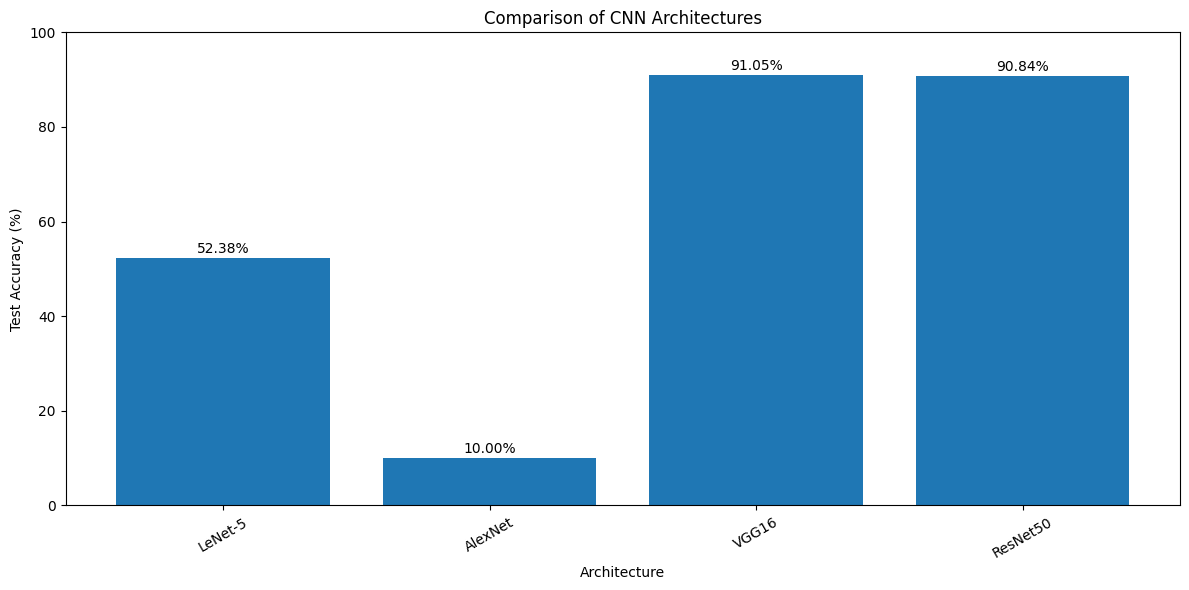

In [93]:


# ============================================================
# PLOT
# ============================================================

plt.figure(figsize=(12, 6))

bars = plt.bar(
    architecture_df["Model"],
    architecture_df["Comparison Accuracy (%)"]
)

plt.xlabel("Architecture")
plt.ylabel("Test Accuracy (%)")

plt.title(
    "Comparison of CNN Architectures"
)

plt.xticks(rotation=30)

# Display accuracy values on top of bars
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"{height:.2f}%",
        ha="center"
    )

plt.ylim(0, 100)

plt.tight_layout()
plt.show()

In [95]:
# Put VGG16's test accuracy into the common Accuracy (%) column

architecture_df.loc[
    architecture_df["Model"] == "VGG16",
    "Accuracy (%)"
] = architecture_df.loc[
    architecture_df["Model"] == "VGG16",
    "Test Accuracy"
]

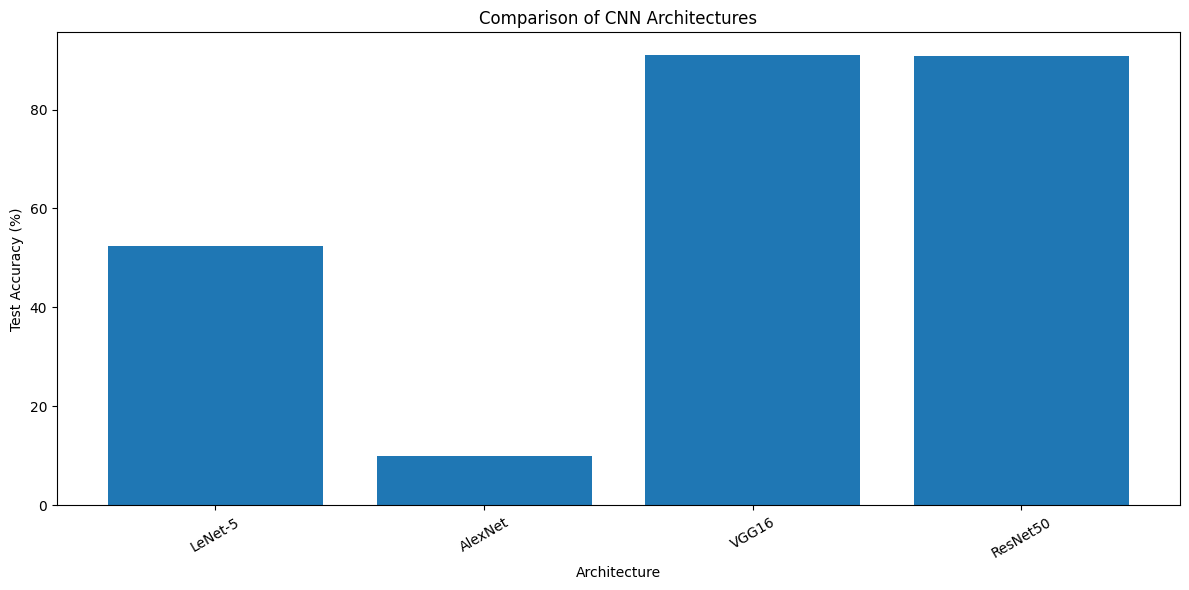

In [96]:
# ============================================================
# ARCHITECTURE ACCURACY COMPARISON
# ============================================================

plt.figure(figsize=(12, 6))

plt.bar(
    architecture_df["Model"],
    architecture_df["Accuracy (%)"]
)

plt.xlabel("Architecture")
plt.ylabel("Test Accuracy (%)")

plt.title(
    "Comparison of CNN Architectures"
)

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

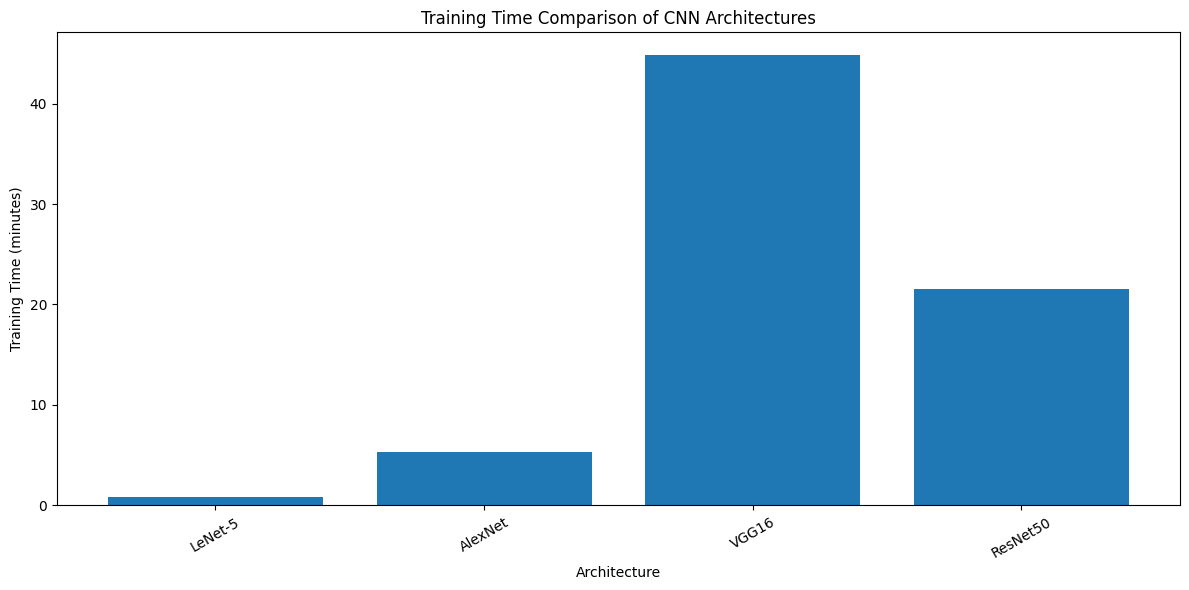

In [97]:
# ============================================================
# TRAINING TIME COMPARISON
# ============================================================

plt.figure(figsize=(12, 6))

plt.bar(
    architecture_df["Model"],
    architecture_df["Training Time (min)"]
)

plt.xlabel("Architecture")
plt.ylabel("Training Time (minutes)")

plt.title(
    "Training Time Comparison of CNN Architectures"
)

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

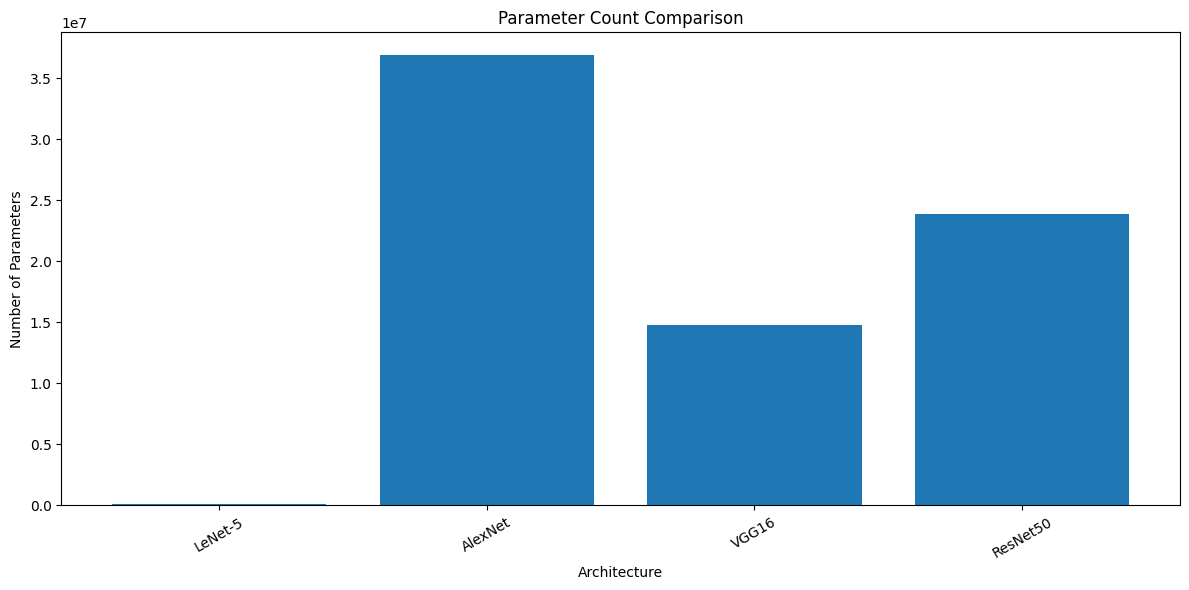

In [98]:
# ============================================================
# PARAMETER COMPARISON
# ============================================================

plt.figure(figsize=(12, 6))

plt.bar(
    architecture_df["Model"],
    architecture_df["Parameters"]
)

plt.xlabel("Architecture")
plt.ylabel("Number of Parameters")

plt.title(
    "Parameter Count Comparison"
)

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [99]:
# ============================================================
# FINAL RESULTS TABLE
# ============================================================

final_results = architecture_df.copy()

final_results[
    "Parameters"
] = final_results[
    "Parameters"
].astype(int)

final_results = final_results[
    [
        "Model",
        "Parameters",
        "Accuracy (%)",
        "Precision (%)",
        "Recall (%)",
        "F1 Score (%)",
        "Training Time (min)"
    ]
]

print(
    final_results.to_string(
        index=False
    )
)

   Model  Parameters  Accuracy (%)  Precision (%)  Recall (%)  F1 Score (%)  Training Time (min)
 LeNet-5       83126         52.38      52.705256       52.38     51.853399             0.798222
 AlexNet    36926730         10.00       1.000000       10.00      1.818182             5.354281
   VGG16    14781642         91.05            NaN         NaN           NaN            44.856806
ResNet50    23851274         90.84      91.001701       90.84     90.837512            21.591613


In [100]:
# ============================================================
# BEST MODEL
# ============================================================

best_model = architecture_df.loc[
    architecture_df["Accuracy (%)"].idxmax()
]

fastest_model = architecture_df.loc[
    architecture_df["Training Time (min)"].idxmin()
]

smallest_model = architecture_df.loc[
    architecture_df["Parameters"].idxmin()
]

print("\n======================================")
print("FINAL COMPARISON")
print("======================================")

print(
    f"Best Accuracy Model : "
    f"{best_model['Model']}"
)

print(
    f"Best Accuracy       : "
    f"{best_model['Accuracy (%)']:.2f}%"
)

print(
    f"Fastest Model       : "
    f"{fastest_model['Model']}"
)

print(
    f"Fastest Training    : "
    f"{fastest_model['Training Time (min)']:.2f} min"
)

print(
    f"Smallest Model      : "
    f"{smallest_model['Model']}"
)

print(
    f"Parameters          : "
    f"{smallest_model['Parameters']:,}"
)


FINAL COMPARISON
Best Accuracy Model : VGG16
Best Accuracy       : 91.05%
Fastest Model       : LeNet-5
Fastest Training    : 0.80 min
Smallest Model      : LeNet-5
Parameters          : 83,126


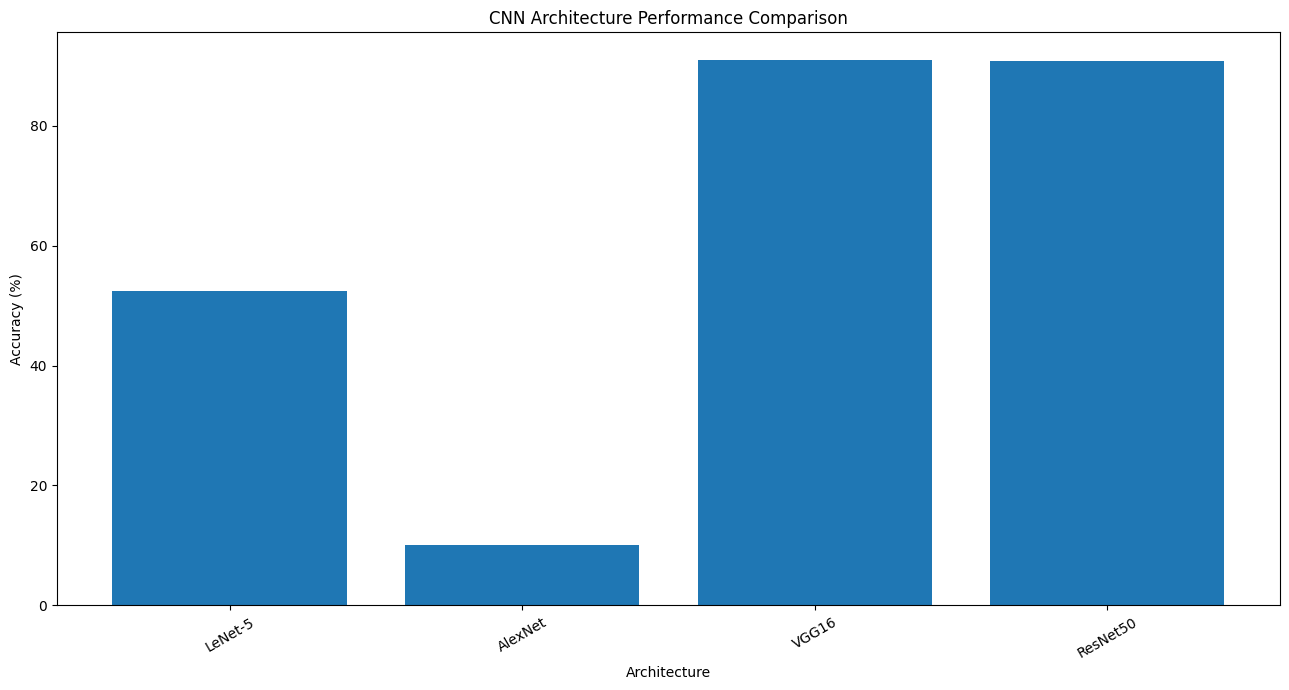

In [101]:
# ============================================================
# ACCURACY + PARAMETER + TRAINING TIME
# ============================================================

fig, ax1 = plt.subplots(
    figsize=(13, 7)
)

x = np.arange(
    len(architecture_df)
)

ax1.bar(
    x,
    architecture_df["Accuracy (%)"]
)

ax1.set_xlabel("Architecture")
ax1.set_ylabel("Accuracy (%)")

ax1.set_xticks(x)

ax1.set_xticklabels(
    architecture_df["Model"],
    rotation=30
)

ax1.set_title(
    "CNN Architecture Performance Comparison"
)

plt.tight_layout()
plt.show()

In [102]:
# ============================================================
# SAVE RESULTS
# ============================================================

architecture_df.to_csv(
    "/kaggle/working/architecture_comparison.csv",
    index=False
)

distribution_df.to_csv(
    "/kaggle/working/class_distribution.csv",
    index=False
)

print("Results saved successfully.")

Results saved successfully.


In [73]:
print("inception_result" in globals())

False
